# EditorNode's lifecycle, and its game twin

**The idea:** the editor and your game are the same kind of thing. Both are a Godot scene tree with one node at the top that runs the show. In your game that node is `_Core`. In the editor it is `EditorNode`.

| | The editor | Your running game |
|---|---|---|
| The program | Godot, in editor mode | Godot, in game mode |
| The top node under `root` | `EditorNode` (built into Godot) | `_Core` (`_core.tscn`, your main scene) |
| Extra pieces loaded at start | Plugins: built-in ones and your addons | Autoloads |
| The list that says what to load | `[editor_plugins]` in `project.godot` | `[autoload]` and `run/main_scene` in `project.godot` |
| Frame loop | Yes, the same one | Yes |

| Section | Contents |
|---|---|
| 1 | One program, two modes |
| 2 | EditorNode's life, step by step |
| 3 | Editor and game, side by side |
| 4 | Who is whose twin |
| 5 | Where your scene lives while you edit it |
| 6 | Two programs when you press Play |
| 7 | What this means for your code |
| 8 | Two trees you can run, and your project's start-up lists |

`EditorNode` is internal to Godot: you cannot script it or subclass it. You reach it through the official doors, `EditorPlugin` and `EditorInterface`. This notebook describes its behaviour at a high level; the exact internal ordering is not verified against Godot's source.


## 1. One program, two modes

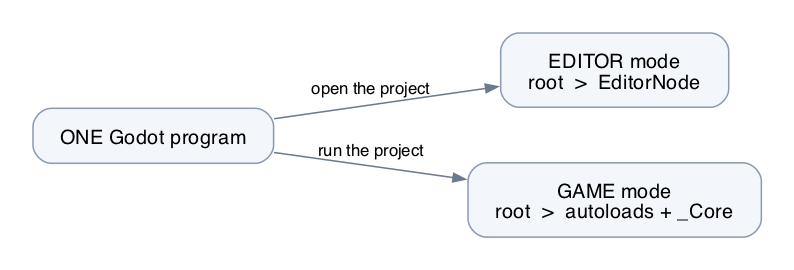

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  bin [label="ONE Godot program"];
  ed [label="EDITOR mode\nroot  >  EditorNode"];
  game [label="GAME mode\nroot  >  autoloads + _Core"];
  bin -> ed [label="open the project"];
  bin -> game [label="run the project"];
}
```

</details>

| Step | Both modes |
|---|---|
| 1 | The program starts and creates a scene tree |
| 2 | The tree gets a `root` (the window) |
| 3 | Something is added under `root` to run the show |

The only difference is step 3: what gets added.

| Mode | Added under `root` |
|---|---|
| Editor | `EditorNode`, which then builds the whole editor interface as its children |
| Game | Your autoloads, then your main scene |

Everything you know about nodes holds from there: children, signals, `_enter_tree`, `_ready`, `_process`, input.


## 2. EditorNode's life

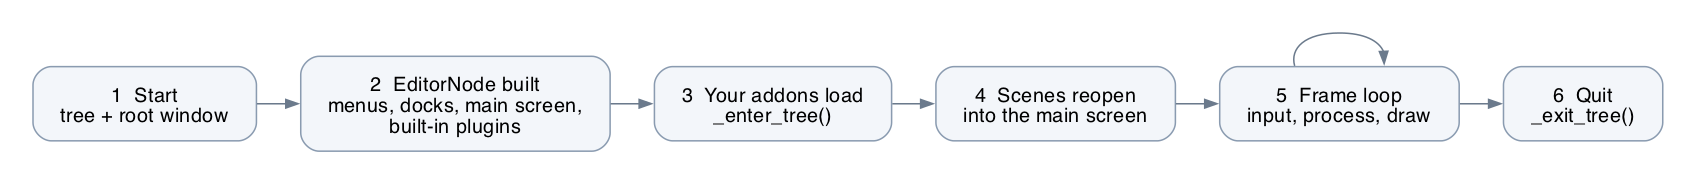

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  nodesep=0.3; ranksep=0.4;
  a [label="1  Start\ntree + root window"];
  b [label="2  EditorNode built\nmenus, docks, main screen,\nbuilt-in plugins"];
  c [label="3  Your addons load\n_enter_tree()"];
  d [label="4  Scenes reopen\ninto the main screen"];
  e [label="5  Frame loop\ninput, process, draw"];
  f [label="6  Quit\n_exit_tree()"];
  a -> b -> c -> d -> e -> f;
  e -> e;
}
```

</details>

| Step | What happens | Where your code gets called |
|---|---|---|
| 1 | Godot starts in editor mode; the tree and `root` exist | Nowhere yet |
| 2 | `EditorNode` is created and builds the interface: menus, docks, Inspector, main screen, bottom panel. It also loads the **built-in** plugins | Nowhere yet |
| 3 | It reads `[editor_plugins]` in `project.godot`, and for each enabled addon creates the `EditorPlugin` from its `plugin.cfg` and adds it to the tree | Your plugin's `_enter_tree()`: register docks, panels, inspector plugins |
| 4 | It reopens the scenes you had open, placing each one inside the main screen | `_ready` etc. on your `@tool` scripts in those scenes |
| 5 | The frame loop runs: input, process, draw, repeat | `_process` and `_input` on your plugins and `@tool` nodes; inspector hooks on every selection |
| 6 | You quit, or disable a plugin | Your plugin's `_exit_tree()`: unregister everything |

**The 2D, 3D and Script views are plugins too.** Godot's own main screens are `EditorPlugin`s (`CanvasItemEditorPlugin`, `Node3DEditorPlugin`, `ScriptEditorPlugin`), loaded in step 2 through the same mechanism your addon uses in step 3. That is why a main-screen tab of yours sits next to them as an equal.

**One difference from a game:** to save power, the editor only redraws when something changes, unless you turn on the editor setting "Update Continuously". A `@tool` script's `_process` still runs.


## 3. Editor and game, side by side

| Step | Editor | Your game |
|---|---|---|
| 1 | Godot starts in editor mode | Godot starts in game mode |
| 2 | Tree and `root` are created | Tree and `root` are created |
| 3 | `EditorNode` is added under `root` and builds the interface | Autoloads are added under `root` (`_Core_Time`, `grab`) |
| 4 | Built-in plugins load, then your enabled addons (`_enter_tree`) | The main scene `_core.tscn` is loaded; `_Core` is added under `root` |
| 5 | Your open scenes are placed inside the main screen | `_Core`'s children enter the tree: `_Starter`, `_RPGM_Viewport`, `_Swiper`, ... (they boot suspended) |
| 6 | Frame loop; redraws only when something changed | Frame loop; redraws every frame |
| 7 | You pick a main-screen tab; the editor shows that one and hides the others | `_Core.change_viewport(...)` shows one viewport and suspends the others |
| 8 | Quit: plugins get `_exit_tree`, then everything is freed | Quit: nodes get `_exit_tree`, then everything is freed |
| **Result** | **A tool for editing files** | **The thing those files describe** |


## 4. Who is whose twin

| In the editor | In your game | What they share |
|---|---|---|
| `EditorNode` | `_Core` | The orchestrator directly under `root`; owns everything else |
| An `EditorPlugin` | An autoload, or a child of `_Core` | A node added at start-up to extend the orchestrator |
| `[editor_plugins] enabled=...` | `[autoload]` + `run/main_scene` | The list in `project.godot` of what to create at start |
| `plugin.cfg` > `script=` | An `[autoload]` line pointing at a script | "Create one of these and add it to the tree" |
| The main screen and its tabs | `Scenes/Scene Grid` and the `Current Viewport` display | Several full-size views; one shown at a time |
| `_make_visible(true / false)` on a plugin | Activate / suspend on a `_Core_Viewport` | "You are the one on screen now" / "you are not" |
| `EditorInterface` | `get_core()` and its getters | The one place to ask for the important parts |
| Registering in `_enter_tree`, unregistering in `_exit_tree` | `_on_viewport_start` / `_on_viewport_finish` | Paired set-up and clean-up |

The rows about the main screen and `_make_visible` are an analogy, not shared code: `_Core` switching viewports and `EditorNode` switching main screens solve the same problem the same way.

| What has no twin | Why |
|---|---|
| The edited scene (section 5) | Only the editor holds a scene it is not actually running |
| `EditorInspectorPlugin` | The Inspector is an editor-only idea |
| Save, undo, the FileSystem scan | Editor-only services |


## 5. Where your scene lives while you edit it

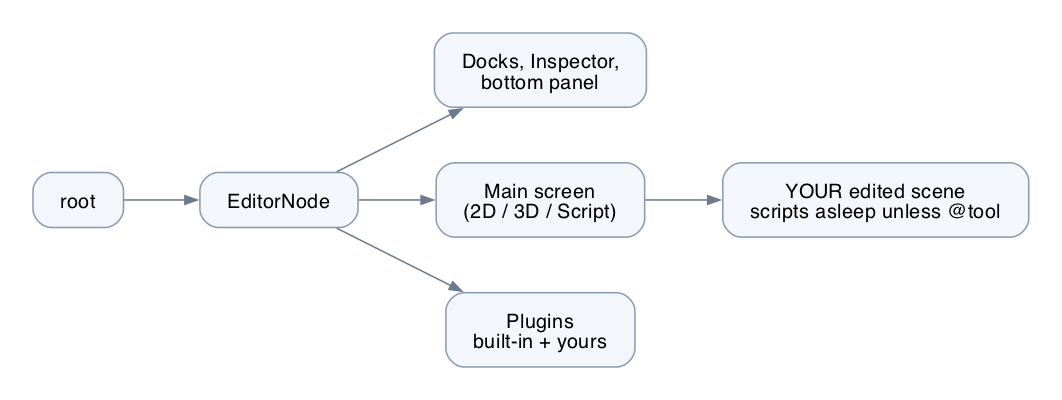

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  root [label="root"];
  en [label="EditorNode"];
  ui [label="Docks, Inspector,\nbottom panel"];
  ms [label="Main screen\n(2D / 3D / Script)"];
  pl [label="Plugins\nbuilt-in + yours"];
  scene [label="YOUR edited scene\nscripts asleep unless @tool"];
  root -> en;
  en -> ui; en -> ms; en -> pl;
  ms -> scene;
}
```

</details>

Your scene is **inside the editor's tree**, as a guest, deep under `EditorNode`.

| | Your scene in the editor | Your scene in the game |
|---|---|---|
| Lives under | The editor's main screen | `root` (the main scene), or under `_Core` |
| Its nodes exist | Yes | Yes |
| Its scripts run | **No**, unless the script is `@tool` | Yes |
| `get_tree().root` is | The editor's root | Your game's root |
| Its parents | Editor nodes | Your nodes |
| `find_parent("_Core")` | `null` when you open `_rpgm_map.tscn` on its own | `_Core` |
| Autoloads | Not there, unless the autoload's script is `@tool` (as far as I know) | There |

That last block is why `@tool` code needs guards. A `@tool` node is running inside someone else's tree, with none of your game around it.


## 6. Two programs when you press Play

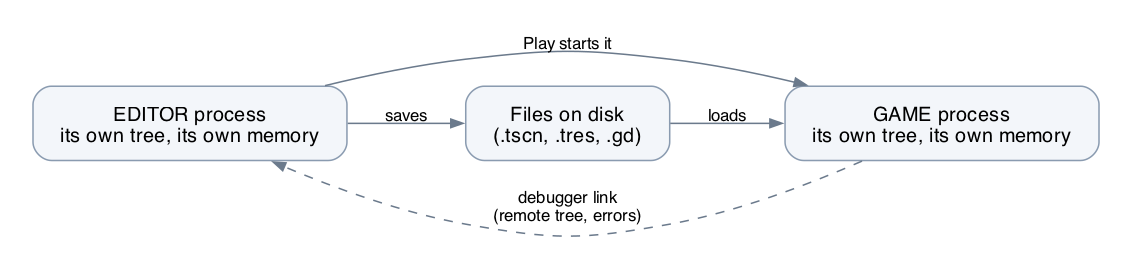

<details><summary>diagram source (graphviz)</summary>

```dot
digraph {
  ed [label="EDITOR process\nits own tree, its own memory"];
  game [label="GAME process\nits own tree, its own memory"];
  disk [label="Files on disk\n(.tscn, .tres, .gd)"];
  ed -> game [label="Play starts it"];
  game -> ed [label="debugger link\n(remote tree, errors)", style=dashed];
  ed -> disk [label="saves"];
  disk -> game [label="loads"];
}
```

</details>

Pressing Play does **not** run your game inside the editor. It starts a second copy of Godot in game mode.

| | Editor process | Game process |
|---|---|---|
| Top node | `EditorNode` | `_Core` |
| Memory | Its own | Its own |
| Live objects (a loaded lambda, a static variable) | One set | A separate set |
| Sees the other's changes | Only through the debugger link | Only by loading files the editor saved |

| Consequence | Example |
|---|---|
| The game changing a value never changes what the Inspector shows | Section "disk vs memory" in `godot-instances-and-shared-resources` |
| The Remote tab in the Scene dock is the game's tree, shown through the link | It is a view, not the same objects |
| An unsaved scene is saved (or the game gets the old file) before the game starts | The game only knows what is on disk |
| A `@tool` error can freeze or crash the editor; a game error cannot | `@tool` code runs **in** the editor process |


## 7. What this means for your code

| Situation | Because | So |
|---|---|---|
| `get_core()` is `null` inside a `@tool` script | In the editor there is no `_Core` above your scene | Guard: return early when a getter is `null` or `Engine.is_editor_hint()` is true |
| A `@tool` node's `_process` runs while you edit | It is a live node in the editor's tree | Keep game logic out of the editor path |
| You want the scene being edited | It is buried under editor nodes | `EditorInterface.get_edited_scene_root()`, never `get_tree().current_scene` |
| A main-screen tab made with `.new()` never appears | `EditorNode` only asks plugins it loaded itself | Put the main-screen hooks on the script your `plugin.cfg` names |
| Plugin code changes do nothing | The plugin node was created at step 3 and is still the old one | Toggle the plugin off and on |
| A static variable set in the game is unset in the editor | Two processes, two memories | Do not expect state to cross; use files |

To see section 5 for real, run this as an `EditorScript` (File > Run in the script editor). I have not run it in your editor.

```gdscript
@tool
extends EditorScript

func _run() -> void:
	var scene := EditorInterface.get_edited_scene_root()
	print("edited scene root: ", scene.name)
	print("its path in the editor's tree: ", scene.get_path())
	print("tree root: ", scene.get_tree().root.name)
```

Expect a long path that starts at `/root`, passes through a node with `EditorNode` in its name, and ends at your scene.


## 8. Two trees you can run

A toy of both modes built by the same function.

In [1]:
class Node:
	def __init__(self, name, *children): self.name, self.children = name, list(children)
	def show(self, depth=0):
		print("   " * depth + self.name)
		for child in self.children: child.show(depth + 1)

def start(mode):
	root = Node("root")                                   # steps 1 and 2: same in both modes
	if mode == "editor":
		root.children.append(Node("EditorNode",
			Node("Docks + Inspector"),
			Node("Main screen",
				Node("2D view", Node("YOUR SCENE (scripts asleep unless @tool)")),
				Node("Script view")),
			Node("Plugins",
				Node("CanvasItemEditorPlugin (built in)"),
				Node("ScriptEditorPlugin (built in)"),
				Node("_rpgm_v2 (yours)"),
				Node("copy_with_path (yours)"))))
	else:
		root.children += [Node("_Core_Time (autoload)"), Node("grab (autoload)")]
		root.children.append(Node("_Core",
			Node("Turner"),
			Node("Scenes/Scene Grid",
				Node("_Starter"), Node("_RPGM_Viewport"), Node("_Swiper"), Node("_DGM"))))
	return root

for mode in ("editor", "game"):
	print(f"--- {mode} mode ---")
	start(mode).show()
	print()

--- editor mode ---
root
   EditorNode
      Docks + Inspector
      Main screen
         2D view
            YOUR SCENE (scripts asleep unless @tool)
         Script view
      Plugins
         CanvasItemEditorPlugin (built in)
         ScriptEditorPlugin (built in)
         _rpgm_v2 (yours)
         copy_with_path (yours)

--- game mode ---
root
   _Core_Time (autoload)
   grab (autoload)
   _Core
      Turner
      Scenes/Scene Grid
         _Starter
         _RPGM_Viewport
         _Swiper
         _DGM



In [2]:
# ----- student scratchpad -----

### Your project's start-up lists

What `project.godot` tells each mode to create (read-only).

In [3]:
import os, re

root = os.getcwd()
while not os.path.exists(os.path.join(root, "project.godot")) and root != "/":
	root = os.path.dirname(root)
text = open(os.path.join(root, "project.godot")).read()

def section(name):
	found = re.search(r"^\[" + re.escape(name) + r"\]\n(.*?)(?=^\[|\Z)", text, re.M | re.S)
	return found.group(1) if found else ""

print("GAME mode creates:")
for name, target in re.findall(r'^(\w+)="\*?([^"]+)"', section("autoload"), re.M):
	print(f"   autoload    {name:<12} {target}")
main = re.search(r'run/main_scene="([^"]+)"', text)
print(f"   main scene  {main.group(1) if main else '(none)'}")

print("\nEDITOR mode creates (on top of the built-in plugins):")
for cfg in re.findall(r'"(res://addons/[^"]+/plugin\.cfg)"', section("editor_plugins")):
	path = os.path.join(root, cfg.replace("res://", ""))
	script = re.search(r'script="([^"]+)"', open(path).read()).group(1) if os.path.exists(path) else "?"
	print(f"   plugin      {os.path.dirname(cfg).replace('res://', ''):<24} script: {script}")

GAME mode creates:
   autoload    _Core_Time   res://core/_core_time.gd
   autoload    grab         uid://cb3jg3nb7ark
   main scene  res://_core.tscn

EDITOR mode creates (on top of the built-in plugins):
   plugin      addons/_rpgm_v2          script: plugin.gd
   plugin      addons/copy_with_path    script: plugin.gd


In [4]:
# ----- student scratchpad -----

| Status of the claims in this notebook | |
|---|---|
| `EditorNode`, the three built-in editor plugin classes and `get_edited_scene_root` exist in your Godot build | Checked against the binary |
| The start-up lists above | Read from your `project.godot` |
| The editor and the game are separate processes | How Godot works |
| The exact order inside steps 2 to 4 of `EditorNode`'s start-up | High-level description; not verified against Godot's source |
| `@tool` autoloads being present in the editor | As far as I know; not verified |
